In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sb


## 1. Carga y descripción


1. Carga el fichero y muestra shape, head() y info().

In [2]:
# Carga del fichero
df = pd.read_csv("Telco-Customer-Churn.csv")

In [3]:
# Muestro shape
df.shape

(7043, 21)

In [4]:
# Muestro head
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
# Muestro info
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

2. ¿Qué variables son numéricas y cuáles categóricas? ¿Alguna numérica está codificada como
texto? (Pista: revisa TotalCharges.)


In [6]:
# Variables numericas
df.select_dtypes(["number"])

,SeniorCitizen,tenure,MonthlyCharges
0,0,1,29.85
1,0,34,56.95
2,0,2,53.85
3,0,45,42.30
4,0,2,70.70
...,...,...,...
7038,0,24,84.80
7039,0,72,103.20
7040,0,11,29.60
7041,1,4,74.40


In [7]:
# Variables de texto
df.select_dtypes(["str", "object"])


,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn
0,7590-VHVEG,Female,Yes,No,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,No
1,5575-GNVDE,Male,No,No,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,1889.5,No
2,3668-QPYBK,Male,No,No,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,108.15,Yes
3,7795-CFOCW,Male,No,No,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),1840.75,No
4,9237-HQITU,Female,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,Yes,Yes,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,1990.5,No
7039,2234-XADUH,Female,Yes,Yes,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),7362.9,No
7040,4801-JZAZL,Female,Yes,Yes,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,346.45,No
7041,8361-LTMKD,Male,Yes,No,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,306.6,Yes


In [8]:
# TotalCharge, es detectada como texto porque tiene 11 valores missing
df["TotalCharges"].value_counts()

TotalCharges
20.2      11
          11
19.75      9
19.9       8
20.05      8
          ..
1990.5     1
7362.9     1
346.45     1
306.6      1
6844.5     1
Name: count, Length: 6531, dtype: int64

In [9]:
# Transformamos TotalCharge a numerica
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

3. Comprueba si hay identificadores que no aportan información al modelo.

In [10]:
# Numero de valores distintos por columnas comparado con el numero de filas
cardinalidad = df.nunique()
print(cardinalidad)

## Customers id no sirve para crear un modelo de prediccion ya que es un identificador y cada valor es diferente asi que lo podemos guardar en otra variable y sacarlos de la tabla
## Churn al ser la variable objetivo tambien la podemos sacar y dejarla como otra variable externa
ids = df["customerID"]
y = df["Churn"]
X = df.drop(columns=["customerID", "Churn"])

customerID          7043
gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
tenure                73
PhoneService           2
MultipleLines          3
InternetService        3
OnlineSecurity         3
OnlineBackup           3
DeviceProtection       3
TechSupport            3
StreamingTV            3
StreamingMovies        3
Contract               3
PaperlessBilling       2
PaymentMethod          4
MonthlyCharges      1585
TotalCharges        6530
Churn                  2
dtype: int64


2. Calidad de los datos

4. Localiza y cuantifica los valores ausentes. ¿En qué variable están y qué porcentaje representan? Propón al menos dos estrategias de tratamiento.

In [11]:
# Ya esta hecho anterior mente en TotalCharges, puedes extraer las instancias como he hecho yo, o puedes calcular la media y sustituir los valores missing por la media

5. ¿Existen filas duplicadas? Justifica.


In [ ]:
dfNoId = pd.concat([X, y], axis = 1)
print(dfNoId.duplicated().sum())

# Existen 22 filas duplicadas, habia que quitar los ids para verlos ya que ninguno se repite evitando ver los duplicados

22


6. Comprueba si el problema está desbalanceado. Calcula la proporción de cada clase y
comenta las implicaciones para el modelado.

In [18]:
print(y.value_counts())

# El problema esta desbalanceado para la clase del no 

Churn
No     5174
Yes    1869
Name: count, dtype: int64


### 3. Análisis univariante


7. Representa la distribución de MonthlyCharges, tenure y TotalCharges (histogramas y
diagramas de caja).


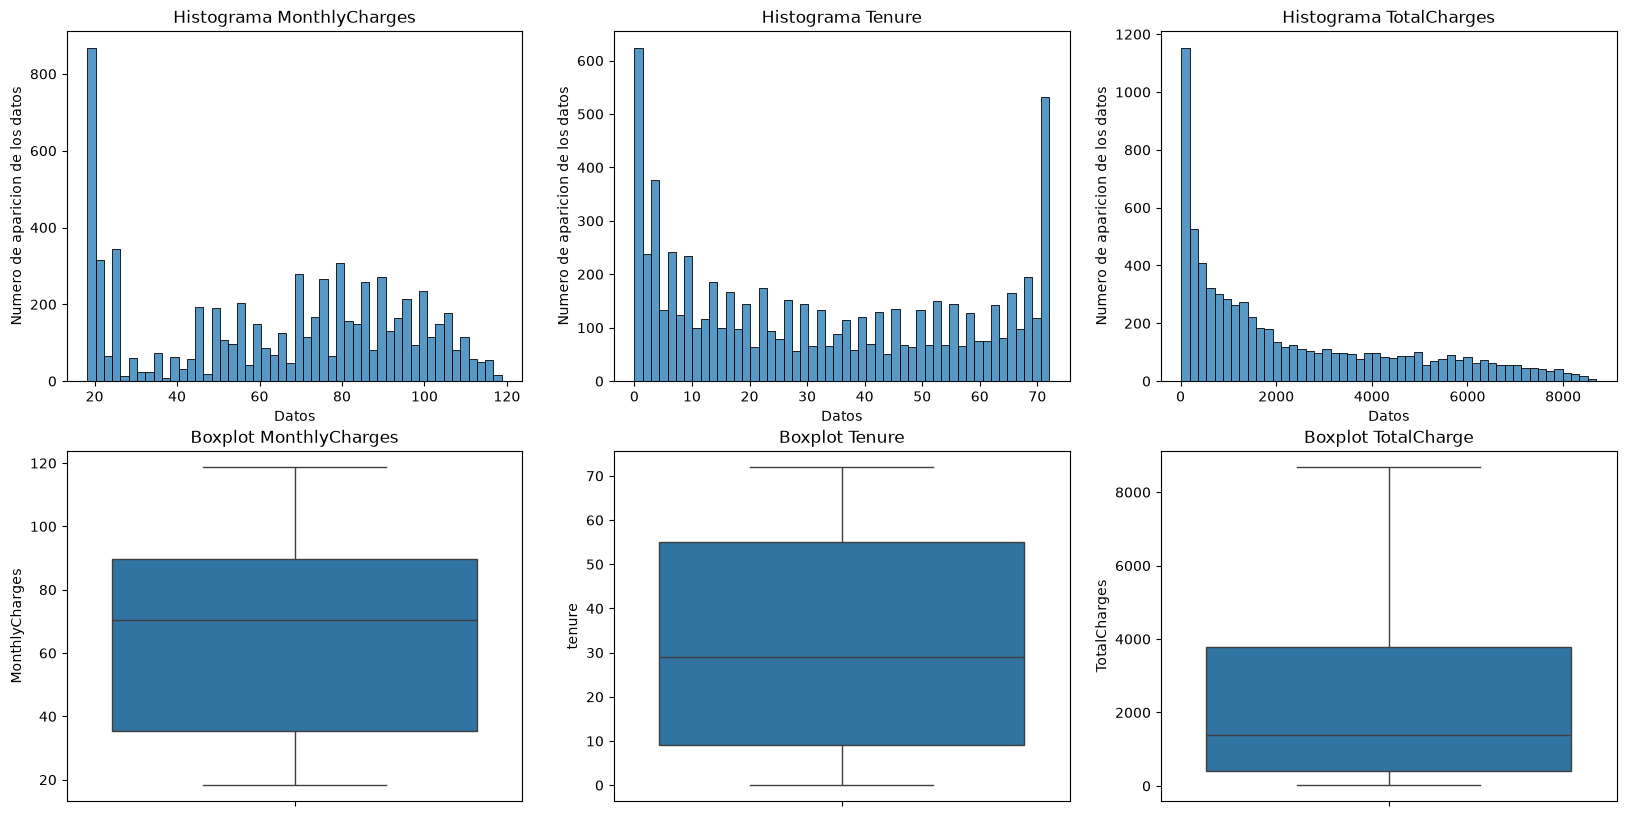

In [ ]:
plt.figure(figsize=[20,10])

plt.subplot(2,3,1)
sb.histplot(data=X["MonthlyCharges"], bins=50)
plt.title("Histograma MonthlyCharges")
plt.xlabel("Datos")
plt.ylabel("Numero de aparicion de los datos")

plt.subplot(2,3,2)
sb.histplot(data=X["tenure"], bins=50)
plt.title("Histograma Tenure")
plt.xlabel("Datos")
plt.ylabel("Numero de aparicion de los datos")

plt.subplot(2,3,3)
sb.histplot(data=X["TotalCharges"], bins=50)
plt.title("Histograma TotalCharges")
plt.xlabel("Datos")
plt.ylabel("Numero de aparicion de los datos")

plt.subplot(2,3,4)
sb.boxplot(data=X["MonthlyCharges"])
plt.title("Boxplot MonthlyCharges")

plt.subplot(2,3,5)
sb.boxplot(data=X["tenure"])
plt.title("Boxplot Tenure")

plt.subplot(2,3,6)
sb.boxplot(data=X["TotalCharges"])
plt.title("Boxplot TotalCharges")

plt.show()


8. Representa la frecuencia de Contract, InternetService y PaymentMethod.

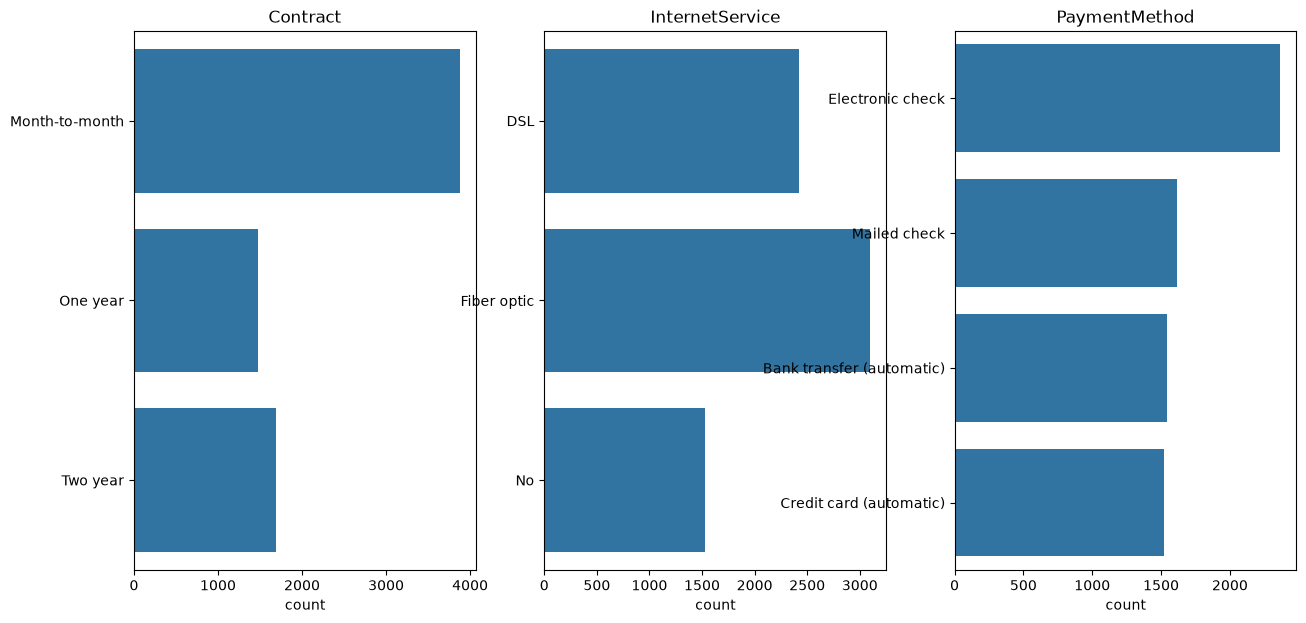

In [43]:
plt.figure(figsize=[15,7])

plt.subplot(1, 3, 1)
sb.countplot(data=X, y="Contract")
plt.title("Contract")
plt.ylabel("")

plt.subplot(1, 3, 2)
sb.countplot(data=X, y="InternetService")
plt.title("InternetService")
plt.ylabel("")

plt.subplot(1, 3, 3)
sb.countplot(data=X, y="PaymentMethod")
plt.title("PaymentMethod")
plt.ylabel("")

plt.show()


9. ¿Qué variables presentan asimetría? ¿Detectas valores atípicos? Razona si son errores o
clientes legítimos.

MonthlyCharges representa asimetria por la izquierda ya que hay muchos mas clientes pagando menos que mas, tiene valores atipicos ya que pasan de pagar la media entre 30-80 a 120 pero no puede ser considerado un error ya que todos los atipicos tienen contratados los mejores servicios que ofrece la empresa

Tenure es asimetrica presenta muchos clientes nuevos y muchos antiguos, representa que la empresa tuvo muchos clientes en su inauguracion, y además tiene un alto volumen de clientes nuevos a corto plazo.

Pues TotalCharges es lo mismo que MonthlyCharges pero multiplicado por 12.

Los clientes tambien prefieren tener contratos en su mayoria de pagar de mes a mes,

La mayoria de clientes prefiere comprar fibra y DSL a no tener internet.

Y el metodo de pago es lo mas simetrico que hay con un pequeño desbalanceo a pago electronico.

In [45]:
print(X[X["MonthlyCharges"] > 118])

      gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
2115  Female              0      No         No      71          Yes   
3894  Female              0     Yes         No      68          Yes   
4586  Female              0     Yes        Yes      72          Yes   
4804  Female              0      No         No      61          Yes   
5127    Male              0      No         No      67          Yes   
6118    Male              0      No         No      72          Yes   

     MultipleLines InternetService OnlineSecurity OnlineBackup  \
2115           Yes     Fiber optic            Yes          Yes   
3894           Yes     Fiber optic            Yes          Yes   
4586           Yes     Fiber optic            Yes          Yes   
4804           Yes     Fiber optic            Yes          Yes   
5127           Yes     Fiber optic            Yes          Yes   
6118           Yes     Fiber optic            Yes          Yes   

     DeviceProtection TechSupport Strea

### 4. Análisis multivariante

10. Calcula la matriz de correlación de las variables numéricas y represéntala con un mapa de
calor. ¿Qué relación observas entre TotalCharges, tenure y MonthlyCharges?.

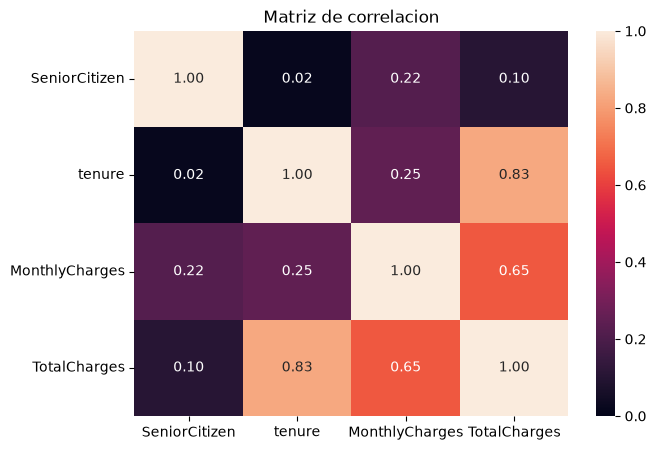

In [47]:
corr = X.select_dtypes("number").corr()

plt.figure(figsize=(7, 5))
sb.heatmap(corr, annot=True, fmt=".2f", vmin=0, vmax=1)
plt.title("Matriz de correlacion")
plt.show()

Se aprecia 0.83 de correlacion con tenure y Totalcharge es decir, que los clientes de misma antiguedad suelen pagar lo mismo.

11. Analiza cómo varía la tasa de Churn según Contract, InternetService y tenure (agrupa
tenure en tramos). Escribe al menos tres reglas del tipo «si A es X entonces el cliente
tiende a abandonar».

Contract
Month-to-month    42.7
One year          11.3
Two year           2.8
Name: Churn_num, dtype: float64 

InternetService
DSL            19.0
Fiber optic    41.9
No              7.4
Name: Churn_num, dtype: float64 

tenure_tramo
0-12     47.4
13-24    28.7
25-48    20.4
49-72     9.5
Name: Churn_num, dtype: float64 



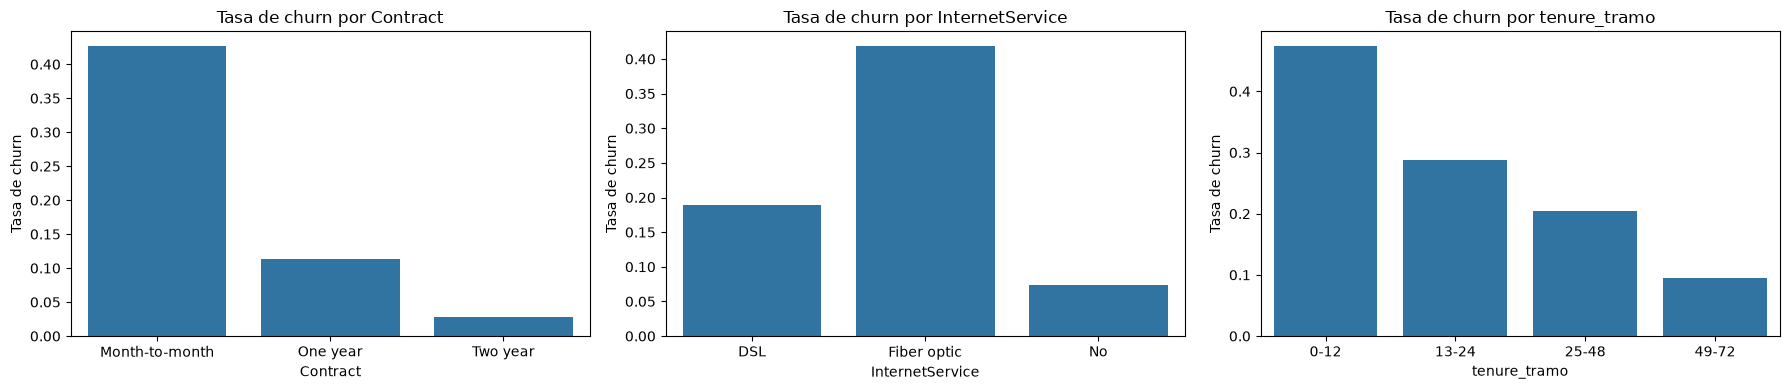

In [48]:
dfNoId["Churn_num"] = (dfNoId["Churn"] == "Yes").astype(int)

dfNoId["tenure_tramo"] = pd.cut(dfNoId["tenure"], bins=[-1, 12, 24, 48, 72], labels=["0-12", "13-24", "25-48", "49-72"])

for c in ["Contract", "InternetService", "tenure_tramo"]:
    print((dfNoId.groupby(c, observed=True)["Churn_num"].mean() * 100).round(1), "\n")


fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, c in zip(axes, ["Contract", "InternetService", "tenure_tramo"]):
    sb.barplot(data=dfNoId, x=c, y="Churn_num", errorbar=None, ax=ax)
    ax.set_title(f"Tasa de churn por {c}")
    ax.set_ylabel("Tasa de churn")
plt.tight_layout()
plt.show()

- Si el cliente tiene Contrato de 2 años no se quedará

- Si el cliente no contrata internet el cliente se quedará.

- Si el cliente tiene una antiguedad mayor a 50 meses no se va a ir

12. ¿Qué combinación de dos o tres variables separa mejor a los clientes que abandonan?


                                             tasa    n
Contract       InternetService tenure_tramo           
Month-to-month Fiber optic     0-12          70.2  916
                               13-24         50.6  425
                               25-48         43.4  521
               DSL             0-12          42.5  690
               Fiber optic     49-72         29.3  266
               DSL             13-24         23.7  232
               No              0-12          22.7  388
One year       Fiber optic     25-48         20.1  154
                               49-72         18.9  355
               DSL             0-12          16.7   42
Month-to-month DSL             25-48         15.9  227
One year       DSL             13-24         13.9   79
Month-to-month DSL             49-72         13.5   74
               No              13-24         10.0   80
One year       DSL             25-48          9.1  241
Two year       Fiber optic     25-48          8.6   35
          

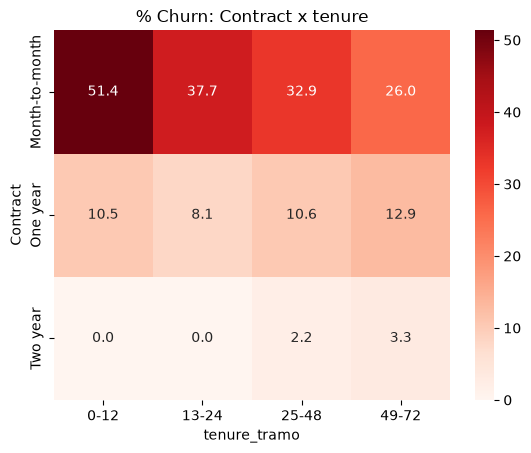

In [50]:
# Combinación de tres variables: tasa de churn y nº de clientes
g = (dfNoId.groupby(["Contract", "InternetService", "tenure_tramo"], observed=True)["Churn_num"]
     .agg(tasa="mean", n="size"))
g["tasa"] = (g["tasa"] * 100).round(1)
print(g[g["n"] >= 30].sort_values("tasa", ascending=False))

tabla = dfNoId.pivot_table(index="Contract", columns="tenure_tramo",
                           values="Churn_num", aggfunc="mean", observed=True) * 100
sb.heatmap(tabla, annot=True, fmt=".1f", cmap="Reds")
plt.title("% Churn: Contract x tenure")
plt.show()

La combinacion que muestra los clientes que mas abandonan es paga Mes a Mes, Fibra Optica y antigüedad de menos de un año

### 5. Conclusiones


13. Resume en cinco viñetas los hallazgos principales.

- El tipo de contrato es el factor mas determinante teniendo 42.7% en Month to Month

- La fibra optica presenta la mayor tasa de abandono con 41.9% clientes que abandonan.

- Los clientes mas antiguos son los mas leales, frente los nuevos que son los que mas abandonan.

- La combinacion que muestra los clientes que mas abandonan es paga Mes a Mes, Fibra Optica y antigüedad de menos de un año

- TotalCharges está fuertemente correlacionada con tenure.

14. Formula una recomendación de negocio concreta orientada a reducir el abandono

Como el segmento mas problematico son los nuevos clientes que pagan mes a mes y fibra optica, a este segmento se le podria a los 2 o 3 meses reformular su contrato con una generosa oferta de un contrato anual o bianual, para asegurar que se queden y reducir la tasa de abandono. Ademas la empresa deberia hacer una revision de la fibra para saber si el problema es el servicio o simplemente el precio para poder ajustarlo.